<a href="https://colab.research.google.com/github/desireesosa/SimulacionII/blob/main/ModeloSIR_pyMC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---

| **Asignatura** | **Estudiante** | **Actividad** |
| :---: | :---: | :---: |
| Simulación II | Desiree Salim Sosa Gomez | Modelo SIR con pyMC |

---

<h1> Modelo SIR con pyMC </h1>

<h4> Modelo SIR </h4>

El modelo SIR (Susceptibles - Infectados - Recuperados) es una formulación matemática determinista fundamentada en ecuaciones diferenciales ordinarias (EDO) que describe la dinámica de transmisión de una enfermedad infecciosa en una población cerrada de tamaño constante $N$, donde:

$$N = S(t) + I(t) + R(t)$$

Las transiciones entre estados se rigen por el siguiente sistema no lineal:

$$\frac{dS}{dt} = -\frac{\beta S I}{N}$$

$$\frac{dI}{dt} = \frac{\beta S I}{N} - \gamma I$$

$$\frac{dR}{dt} = \gamma I$$

#### Interpretación de los Parámetros

* **$\beta$ (Tasa de Contacto Infeccioso):** Frecuencia media de contactos efectivos por unidad de tiempo capaces de transmitir la infección de un individuo infectado a uno susceptible.
* **$\gamma$ (Tasa de Remisión/Recuperación):** Proporción de la población infectada que se recupera o aísla por unidad de tiempo. El inverso $1/\gamma$ representa la duración media del periodo infeccioso.
* **$R_0$ (Número Reproductivo Básico):** Representa el número promedio de casos secundarios originados por un solo individuo infectado en una población completamente susceptible. Matemáticamente se define como:

$$R_0 = \frac{\beta}{\gamma}$$

<h3> Datos sinteticos </h3>

En ausencia de una serie temporal real de una epidemia en desarrollo, se procede a generar un entorno de datos sintéticos controlados. Definimos un sistema dinámico cerrado de tipo SIR con una población fija de $N = 10,000$ personas, con 15 infectados iniciales y sin recuperados al día 0.

Las dinámicas de contagio y recuperación nominales están gobernadas por las tasas conocidas:
* $\beta_{\text{nominal}} = 0.30$
* $\gamma_{\text{nominal}} = 0.11$

Con estos valores, resolvemos las ecuaciones diferenciales mediante un integrador numérico.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

In [ ]:
#Semilla
np.random.seed(42)

N_poblacion = 10_000
I_inicio, R_inicio = 15.0, 0.0
S_inicio = N_poblacion - I_inicio - R_inicio

beta_verdad = 0.30
gamma_verdad = 0.11
vector_dias = np.arange(0, 51, dtype=float)
sigma_ruido = 0.12  #Desviación


In [ ]:
#Definimos
def deriv_sir_poblacional(t, y, beta, gamma):
    S_t, I_t, R_t = y
    tasa_contagios = beta * S_t * I_t / N_poblacion
    tasa_recuperados = gamma * I_t
    return [-tasa_contagios, tasa_contagios - tasa_recuperados, tasa_recuperados]

#Integración
solucion_exacta = solve_ivp(
    deriv_sir_poblacional,
    (vector_dias[0], vector_dias[-1]),
    [S_inicio, I_inicio, R_inicio],
    t_eval=vector_dias,
    args=(beta_verdad, gamma_verdad)
)

assert solucion_exacta.success, "La integración determinista falló"
S_real, I_real, R_real = solucion_exacta.y

ruido_lognormal = np.random.normal(loc=0.0, scale=sigma_ruido, size=len(I_real))
infectados_medidos = np.exp(np.log(I_real + 1.0) + ruido_lognormal) - 1.0
infectados_medidos = np.maximum(infectados_medidos, 0.0)

Primeros días simulados
   dia  I_teorico  I_observado
0    0  15.000000    15.982687
1    1  18.129283    17.814514
2    2  21.908161    23.759664
3    3  26.468609    31.976904
4    4  31.971147    31.057605


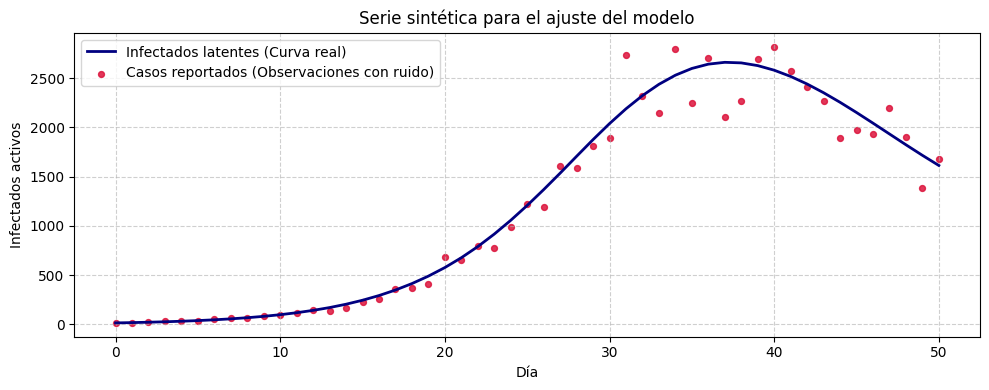

In [ ]:
#Graficación
df_sintetico = pd.DataFrame({
    "dia": vector_dias.astype(int),
    "I_teorico": I_real,
    "I_observado": infectados_medidos
})

print("Primeros días simulados")
print(df_sintetico.head())

plt.figure(figsize=(10, 4))
plt.plot(vector_dias, I_real, label="Infectados latentes (Curva real)", color="navy", linewidth=2)
plt.scatter(vector_dias, infectados_medidos, color="crimson", s=18, alpha=0.85, label="Casos reportados (Observaciones con ruido)")
plt.xlabel("Día")
plt.ylabel("Infectados activos")
plt.title("Serie sintética para el ajuste del modelo")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

<h3> Modelo estadistico Bayesiano </h3>

Con base en la regla de actualización bayesiana, la probabilidad conjunta *a posteriori* de los parámetros desconocidos $(\beta, \gamma)$ condicionada a los datos observados $\mathbf{y}$ viene dada por:

$$p(\beta, \gamma \mid \mathbf{y}) \propto p(\mathbf{y} \mid \beta, \gamma) \cdot p(\beta) \cdot p(\gamma)$$

>Distribuciones a Priori (Priors).

Para garantizar que los parámetros biológicos $(\beta, \gamma)$ adopten valores estrictamente positivos y físicamente coherentes, se asignan distribuciones a priori de tipo Lognormal. Este enfoque evita la necesidad de imponer fronteras rígidas o distribuciones uniformes acotadas, permitiendo una exploración continua del espacio de parámetros centrada en órdenes de magnitud epidemiológicamente plausibles:   

$$\beta \sim \text{LogNormal}\left(\mu = \ln(0.30), \, \sigma = 0.55\right)$$$$\gamma \sim \text{LogNormal}\left(\mu = \ln(0.11), \, \sigma = 0.55\right)$$

>Estructura de Verosimilitud

El mecanismo de generación de datos considera un error de observación multiplicativo en los conteos de individuos infectados $y_t$. Para modelar esta variabilidad estocástica, se aplica una transformación logarítmica estabilizadora de la varianza.

$$\ln(y_t + 1) \sim \mathcal{N}\left(\ln\left(I_t(\beta, \gamma) + 1\right), \, \sigma_{\text{obs}}^2\right)$$

>Esquema de Integración Númerica

Debido a que el modelo SIR no posee una solución analítica en forma cerrada, la trayectoria temporal de la epidemia se resuelve numéricamente. Se implementa de forma Explícita un algoritmo de Runge-Kutta de cuarto orden (RK4) con discretización temporal fija $\Delta t = 1 \text{ día}$. **Esta aproximación permite propagar eficientemente los estados del sistema dinámico en cada evaluación de la función de verosimilitud durante el muestreo MCMC.**

In [ ]:
def sir_rk4_np(beta, gamma, pasos=50):
    estado = np.array([S_inicio, I_inicio, R_inicio], dtype=float)
    historia = [estado.copy()]
    for _ in range(pasos):
        def f(v):
            S, I, R = v
            q = beta * S * I / N_poblacion
            g = gamma * I
            return np.array([-q, q - g, g])
        k1 = f(estado)
        k2 = f(estado + k1 / 2)
        k3 = f(estado + k2 / 2)
        k4 = f(estado + k3)
        estado = estado + (k1 + 2*k2 + 2*k3 + k4) / 6
        historia.append(estado.copy())
    return np.stack(historia)

trayectoria_rk4 = sir_rk4_np(beta_verdad, gamma_verdad, pasos=len(vector_dias) - 1)
error = np.max(np.abs(trayectoria_rk4 - solucion_exacta.y.T))
print(f"Error máximo frente a solve_ivp: {error:.5f} personas")
assert error < 20.0, f"Revisar parámetros: el error fue de {error:.2f}"

# 3. Integrador RK4 en PyTensor (simbólico para PyMC)
def sir_rk4_pt(beta, gamma, pasos=50):
    estado = pt.stack([
        pt.as_tensor_variable(S_inicio),
        pt.as_tensor_variable(I_inicio),
        pt.as_tensor_variable(R_inicio)
    ])
    estados = [estado]
    def f(v):
        S, I, R = v[0], v[1], v[2]
        q = beta * S * I / N_poblacion
        g = gamma * I
        return pt.stack([-q, q - g, g])
    for _ in range(pasos):
        k1 = f(estado)
        k2 = f(estado + k1 / 2)
        k3 = f(estado + k2 / 2)
        k4 = f(estado + k3)
        estado = estado + (k1 + 2*k2 + 2*k3 + k4) / 6
        estados.append(estado)
    return pt.stack(estados)

Error máximo frente a solve_ivp: 15.41790 personas


In [ ]:
with pm.Model() as modelo_sir:
    beta = pm.LogNormal("beta", mu=np.log(0.30), sigma=0.55)
    gamma = pm.LogNormal("gamma", mu=np.log(0.11), sigma=0.55)

    trayectoria = sir_rk4_pt(beta, gamma, pasos=len(vector_dias) - 1)
    I_modelo = trayectoria[:, 1]

    R0_basico = pm.Deterministic("R0_basico", beta / gamma)

    pm.Normal(
        "log_infectados",
        mu=pt.log(I_modelo + 1),
        sigma=sigma_ruido,
        observed=np.log(infectados_medidos + 1)
    )

# Ejecución del muestreador NUTS
with modelo_sir:
    idata = pm.sample(
        draws=800,
        tune=800,
        chains=2,
        cores=1,
        random_seed=42,
        target_accept=0.92,
        return_inferencedata=True
    )

print("Muestreo completado con éxito.")